

**Participant:** Noor ul Eman &nbsp;|&nbsp; **Roll no.:** SE-25064 &nbsp;|&nbsp; **Stretch module chosen:** Module 04 — *The Erased Measurement*

**Contents**
0. Setup
1. Module 01 · The Gatekeeper (mandatory)
2. Module 03 · The Two Observers (mandatory)
3. Module 05 · The Damaged Message (mandatory)
4. Module 04 · The Erased Measurement (stretch)



## 0 · Setup

In [ ]:
%pip install -q qiskit qiskit-aer pylatexenc matplotlib numpy

import itertools
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, state_fidelity, partial_trace
from qiskit.visualization import plot_histogram
import qiskit

sim = AerSimulator()          # a simulated quantum computer
print("Qiskit version:", qiskit.__version__)

def run(circuit, shots=1000):
    """Run a circuit `shots` times and return a dict of outcome counts."""
    return sim.run(transpile(circuit, sim), shots=shots).result().get_counts()

# Qiskit prints bit strings with the HIGHEST-index bit on the LEFT:
# counts key '10' means classical bit 1 = 1 and classical bit 0 = 0.
print("Ready.")

Note: you may need to restart the kernel to use updated packages.


Qiskit version: 2.6.0
Ready.


---
## 1 · MODULE 01 — The Gatekeeper *(mandatory)*
*Allowed gates: H, X, measure. One and two qubits.*

Qubits start in |0⟩. Two gates matter here:
- **X** flips |0⟩ ↔ |1⟩ (a quantum NOT).
- **H** (Hadamard) turns |0⟩ into an equal superposition (|0⟩+|1⟩)/√2. Measuring it gives 0 or 1 with probability ½ each.

### 🥉 Bronze — a bit that is always 1, and a bit that is perfectly uncertain

Always-1 bit : {'1': 1000}


50/50 bit    : {'1': 483, '0': 517}


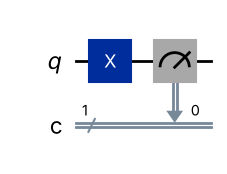

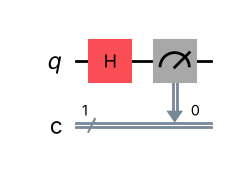

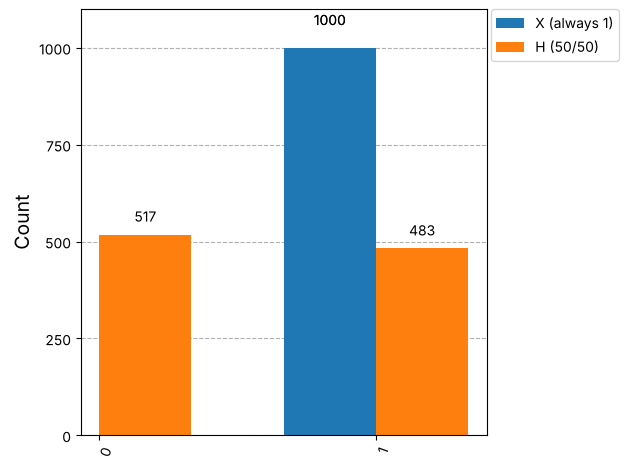

In [ ]:
# Key 1: always 1  ->  X then measure
k1 = QuantumCircuit(1, 1)
k1.x(0)
k1.measure(0, 0)
c1 = run(k1, 1000)
print("Always-1 bit :", c1)

# Key 2: perfectly uncertain  ->  H then measure
k2 = QuantumCircuit(1, 1)
k2.h(0)
k2.measure(0, 0)
c2 = run(k2, 1000)
print("50/50 bit    :", c2)

display(k1.draw("mpl")); display(k2.draw("mpl"))
plot_histogram([c1, c2], legend=["X (always 1)", "H (50/50)"])

**What it proves:** X is deterministic (|0⟩→|1⟩, probability 1). H gives amplitudes (1/√2, 1/√2), so P(0)=P(1)=|1/√2|²=½. The counts wobble around 500/500 because 1000 shots is a finite sample.

### 🥈 Silver — a bit that *looks* uncertain but is secretly certain
Two gates: **H then H**. After the first H the qubit is in superposition (it *looks* random). The second H recombines the two amplitudes and they interfere.

State after H,H (before measuring): [1.+0.j 0.+0.j]
Counts: {'0': 1000}


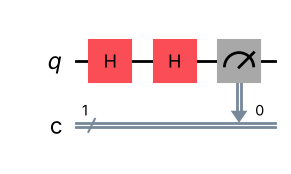

In [ ]:
sec = QuantumCircuit(1, 1)
sec.h(0)
sec.h(0)
print("State after H,H (before measuring):", np.round(Statevector(sec).data, 6))
sec.measure(0, 0)
c_sec = run(sec, 1000)
print("Counts:", c_sec)
display(sec.draw("mpl"))

**Why it happens:** H|0⟩ = (|0⟩+|1⟩)/√2. Applying H again:
H(|0⟩+|1⟩)/√2 = ½[(|0⟩+|1⟩) + (|0⟩−|1⟩)] = |0⟩.
The |1⟩ terms have opposite signs and **cancel** (destructive interference); the |0⟩ terms add. H is its own inverse (H·H = I), so the sequence is secretly the identity. Randomness appears only if you *measure in the middle* (see Module 04).

### 🥇 Gold — the vault code **101**, built from **000**
Three qubits start at 000. Flip the first and the third with X, then measure.

Vault measured: {'101': 1000}


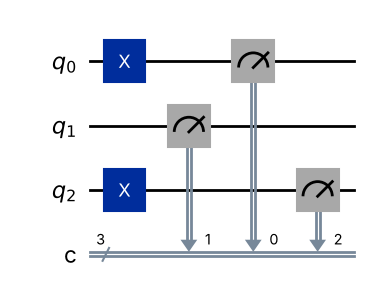

Only qubit 0 flipped gives: {'001': 100}  <- printed '001': qubit 0 is the RIGHTMOST character


In [ ]:
vault = QuantumCircuit(3, 3)
vault.x(0)      # qubit 0 -> 1
vault.x(2)      # qubit 2 -> 1   (qubit 1 stays 0)
vault.measure([0, 1, 2], [0, 1, 2])
c_vault = run(vault, 1000)
print("Vault measured:", c_vault)
display(vault.draw("mpl"))

# Bit-order check: 101 is a palindrome, so order doesn't matter here. Prove we understand it:
chk = QuantumCircuit(3, 3); chk.x(0); chk.measure([0,1,2],[0,1,2])
print("Only qubit 0 flipped gives:", run(chk, 100), " <- printed '001': qubit 0 is the RIGHTMOST character")
assert c_vault == {"101": 1000}

**What it proves:** we can prepare an exact classical bit pattern from |000⟩ using only X gates; measurement is deterministic when the state is a computational-basis state.

**Module 01 summary — answer:** keys = X (always 1), H (50/50), H·H (looks random, always 0); vault code = `101` via X on qubits 0 and 2.

---
## 2 · MODULE 03 — The Two Observers *(mandatory — the heart of the case)*
*Gates: H, X, CNOT, measure. Two detectors, no shared wire.*

### 🥉 Bronze — a pair that only ever agrees (00 and 11, never 01/10)
H puts qubit 0 into superposition; CNOT (control 0, target 1) copies its basis value onto qubit 1 *coherently*, producing the Bell state (|00⟩+|11⟩)/√2.

Bell state amplitudes (|00>,|01>,|10>,|11>): [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]


Counts: {'00': 991, '11': 1009}


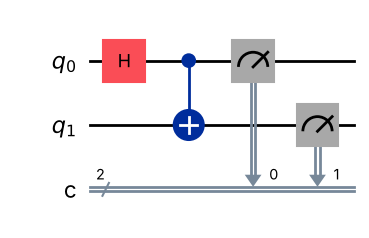

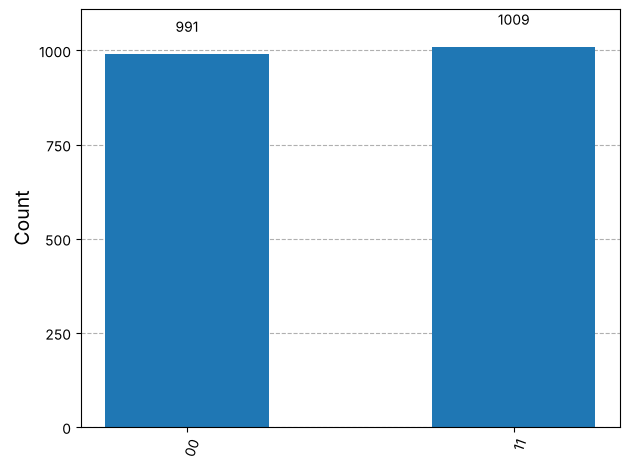

In [ ]:
bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
print("Bell state amplitudes (|00>,|01>,|10>,|11>):", np.round(Statevector(bell).data, 4))
bell.measure([0, 1], [0, 1])
c_bell = run(bell, 2000)
print("Counts:", c_bell)
display(bell.draw("mpl"))
plot_histogram(c_bell)

**What it proves:** the two detectors always agree and each one alone is 50/50. That is exactly what Zara observed. The question is what this agreement *means*.

### 🥈 Silver — a pre-agreed secret coin-flip would also always agree
Classical model: before separating, the two observers flip **one** coin and each takes a copy of the result. No quantum physics, no link, no wire.

Pre-agreed secret : {'00': 986, '11': 1014}
Quantum Bell pair : {'00': 991, '11': 1009}


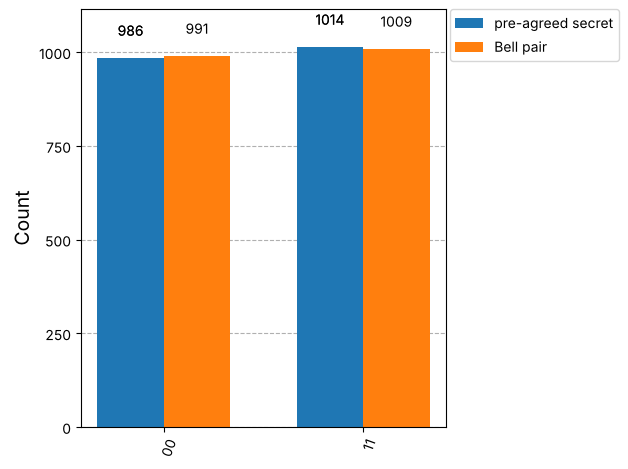

In [ ]:
rng = np.random.default_rng(seed=1)
shots = 2000
secret = rng.integers(0, 2, size=shots)         # the pre-agreed coin flip, one per round
alice = secret.copy()                             # Alice just reads her copy
bob   = secret.copy()                             # Bob reads his copy
classical_counts = {}
for a, b in zip(alice, bob):
    key = f"{b}{a}"                               # same formatting as Qiskit (qubit1 qubit0)
    classical_counts[key] = classical_counts.get(key, 0) + 1
print("Pre-agreed secret :", classical_counts)
print("Quantum Bell pair :", c_bell)
plot_histogram([classical_counts, c_bell], legend=["pre-agreed secret", "Bell pair"])

**Argument:** the two histograms are indistinguishable. *Always agreeing, measured one way, does not prove a quantum link.* A shared secret (a "hidden variable") reproduces it perfectly. Agreement = correlation, and correlation is cheap: two matching copies of a newspaper are correlated too. Nothing was *sent* between the detectors in the classical model, and by the same token the agreement alone shows nothing was sent in the quantum model either.

### 🥇 Gold — an experiment that separates a real quantum pair from a pre-agreed secret
Idea: let each side choose **which way to measure** (a different angle in the X–Z plane). A pre-agreed secret can only hard-code an answer for each possible question in advance. John Bell (1964) and Clauser–Horne–Shimony–Holt (CHSH, 1969) showed that any such local strategy obeys

  **S = E(a₀,b₀) + E(a₀,b₁) + E(a₁,b₀) − E(a₁,b₁) ≤ 2**,

where E is the correlation (P(same) − P(different)) for the chosen settings. A Bell pair can reach **2√2 ≈ 2.83**.

*(Ry rotations go slightly beyond H/X/CNOT. It's the minimum extra ingredient needed: H and X alone only measure in Z and X, and a secret can fake both of those — see the cell after next.)*

**Step 1 — the best any pre-agreed secret can do (exhaustive check):**

In [ ]:
# A "pre-agreed secret" = each side has a fixed answer (+1/-1) for each of its two settings.
# There are only 2^4 = 16 deterministic strategies. Mixing them (shared randomness) can't beat the best one.
best = -9
for a0, a1, b0, b1 in itertools.product([+1, -1], repeat=4):
    S = a0*b0 + a0*b1 + a1*b0 - a1*b1
    best = max(best, S)
print("Maximum S for ANY pre-agreed secret strategy:", best)

Maximum S for ANY pre-agreed secret strategy: 2


**Step 2 — the same game with a real Bell pair.** Alice measures along angle a₀=0 or a₁=π/2, Bob along b₀=π/4 or b₁=−π/4. To measure along angle θ we rotate with `ry(-θ)` and then measure in the usual Z way.

In [ ]:
def corr(theta_a, theta_b, shots=8000):
    """Correlation E = P(same) - P(different) for a Bell pair measured at the given angles."""
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)              # Bell pair
    qc.ry(-theta_a, 0)                # Alice's chosen measurement direction
    qc.ry(-theta_b, 1)                # Bob's chosen measurement direction
    qc.measure([0, 1], [0, 1])
    c = run(qc, shots)
    same = c.get("00", 0) + c.get("11", 0)
    return (same - (shots - same)) / shots

a0, a1 = 0, np.pi/2
b0, b1 = np.pi/4, -np.pi/4
E00, E01, E10, E11 = corr(a0, b0), corr(a0, b1), corr(a1, b0), corr(a1, b1)
S = E00 + E01 + E10 - E11
print(f"E(a0,b0)={E00:+.3f}  E(a0,b1)={E01:+.3f}  E(a1,b0)={E10:+.3f}  E(a1,b1)={E11:+.3f}")
print(f"CHSH  S = {S:.3f}   (classical limit 2, quantum maximum {2*np.sqrt(2):.3f})")
assert S > 2.4, "should clearly beat the classical bound of 2"
print("Note: S can land slightly above 2.828 by chance (finite shots: each E has statistical noise: S varies by about +/-0.016 from run to run; averaging 40 runs gives 2.827). This is sampling noise, not a violation of the quantum maximum.")

E(a0,b0)=+0.707  E(a0,b1)=+0.707  E(a1,b0)=+0.695  E(a1,b1)=-0.715
CHSH  S = 2.824   (classical limit 2, quantum maximum 2.828)
Note: S can land slightly above 2.828 by chance (finite shots: each E has statistical noise: S varies by about +/-0.016 from run to run; averaging 40 runs gives 2.827). This is sampling noise, not a violation of the quantum maximum.


**Note on S slightly above 2.828:** each correlation comes from a finite number of shots (8000 here), so it carries statistical noise (S varies by about ±0.016 from run to run; I checked: the average over 40 runs is 2.827, and one 400,000-shot run gives 2.831), and S can randomly land a little above the theoretical quantum maximum 2√2 ≈ 2.828 (or below it). This is sampling fluctuation, **not** a violation of the quantum maximum. Re-running gives values scattered around 2.83.

**What it proves:** S ≈ 2.8 > 2. No pre-agreed secret can do that, so the Bell pair's agreement is **not** explained by a shared classical coin flip. That settles "was it quantum?": yes.

**Why a simpler test isn't enough:** if both sides measure only in Z, or only in X, a secret that stores *both* a Z-answer and an X-answer fakes it. Only the *angled* choices (incompatible settings) break the classical model.

### The crux — could the detectors *send a message*? (No-signalling check)
Suppose Alice tries to signal Bob by choosing what she does to her qubit. If entanglement carried messages, Bob's statistics would change with her choice. We test: Bob always measures Z; Alice does (a) nothing, (b) X, (c) H, (d) measures first.

In [ ]:
def bob_p1(alice_action, shots=8000):
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)
    if alice_action == "x":   qc.x(0)
    if alice_action == "h":   qc.h(0)
    if alice_action == "measure": qc.measure(0, 0)
    qc.measure(1, 1)                                # only Bob's result is recorded in bit 1
    c = run(qc, shots)
    return sum(v for k, v in c.items() if k[0] == "1") / shots   # leftmost char = classical bit 1 = Bob

for action in ["nothing", "x", "h", "measure"]:
    print(f"Alice does {action:<8} -> P(Bob sees 1) = {bob_p1(action):.3f}")

Alice does nothing  -> P(Bob sees 1) = 0.500


Alice does x        -> P(Bob sees 1) = 0.508
Alice does h        -> P(Bob sees 1) = 0.498


Alice does measure  -> P(Bob sees 1) = 0.504


**What it proves:** whatever Alice does, Bob's own results stay 50/50 (within sampling noise). Bob can learn something only by *comparing notes* with Alice over an ordinary channel. Entanglement gives correlation that is **stronger than classical** (Bell violation) but it **cannot transmit information** — the *no-signalling theorem*. So the twin detectors could *agree*, not *send*. ECHO's "faster-than-light message" was an echo, not a voice.

**Module 03 summary — answers:** Bronze: H + CNOT. Silver: a pre-agreed coin gives identical histograms, so agreement ≠ proof of a quantum link. Gold: CHSH test (S≈2.8 > 2) separates them; plus no-signalling check shows no message passes.

---
## 3 · MODULE 05 — The Damaged Message *(mandatory)*
Each original bit was sent **three times** (a *repetition code*); at most one of each three flipped. Recover the message by **majority vote**.

### 🥉 Bronze — recover the original message

In [ ]:
stream = '''100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011
000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111'''.split()
print("Triples received:", len(stream), "->", len(stream) * 3, "bits")

def majority(triple):
    return "1" if triple.count("1") >= 2 else "0"

decoded_bits = "".join(majority(t) for t in stream)
print("Decoded bits :", decoded_bits, f"({len(decoded_bits)} bits)")

# group into 8-bit bytes -> ASCII characters
message = "".join(chr(int(decoded_bits[i:i+8], 2)) for i in range(0, len(decoded_bits), 8))
print("Message      :", message)

flipped = [(i, t) for i, t in enumerate(stream) if t not in ("000", "111")]
print(f"{len(flipped)} of {len(stream)} triples were not uniform, i.e. contained exactly one flipped bit.")
assert message == "ECHO"

Triples received: 32 -> 96 bits
Decoded bits : 01000101010000110100100001001111 (32 bits)
Message      : ECHO
20 of 32 triples were not uniform, i.e. contained exactly one flipped bit.


**What it proves:** with at most one flip per triple, the majority value is always the original bit, so the 32 recovered bits read **E C H O** in ASCII (01000101 01000011 01001000 01001111). Zara's last word was the name of her experiment. (Her hidden "note beneath it" is revealed by the event platform after you submit the answer — add it to the evidence board.)

### 🥈 Silver — where majority vote breaks
It fails when **two or more** of the three bits flip: the wrong value then holds the majority.

In [ ]:
sent = "0"
print("Sent 0 -> 000.  Received  | flips | majority says | correct?")
for rx in ["".join(p) for p in itertools.product("01", repeat=3)]:
    flips = sum(1 for bit in rx if bit != sent)
    m = majority(rx)
    print(f"                 {rx}      |   {flips}   |      {m}        | {'yes' if m == sent else 'NO  <-- breaks here'}")

# how does the error rate behave as the per-bit flip probability p grows?
print("\nper-bit flip prob p -> error rate after majority vote = 3p^2 - 2p^3")
for p in [0.01, 0.05, 0.1, 0.3, 0.5]:
    print(f"  p={p:<5}  raw error {p:<5}  after vote {3*p**2 - 2*p**3:.4f}")

Sent 0 -> 000.  Received  | flips | majority says | correct?
                 000      |   0   |      0        | yes
                 001      |   1   |      0        | yes
                 010      |   1   |      0        | yes
                 011      |   2   |      1        | NO  <-- breaks here
                 100      |   1   |      0        | yes
                 101      |   2   |      1        | NO  <-- breaks here
                 110      |   2   |      1        | NO  <-- breaks here
                 111      |   3   |      1        | NO  <-- breaks here

per-bit flip prob p -> error rate after majority vote = 3p^2 - 2p^3
  p=0.01   raw error 0.01   after vote 0.0003
  p=0.05   raw error 0.05   after vote 0.0073
  p=0.1    raw error 0.1    after vote 0.0280
  p=0.3    raw error 0.3    after vote 0.2160
  p=0.5    raw error 0.5    after vote 0.5000


**Where it breaks:** exactly at **2 flips in one triple** (e.g. `000 → 011`): the vote confidently returns `1`, and nothing in the data shows it was wrong. It helps only while flips are rare (small p: 3p² ≪ p); at p = 0.5 it gives no benefit.

### 🥇 Gold — correct vs. notice, and why you can't "copy a qubit three times"

In [ ]:
print("Flips in a triple | decoder output (majority) | detect-only check (not all equal?)")
for n in range(4):
    rx = "".join("1" if i < n else "0" for i in range(3))   # send 0, flip n bits
    print(f"        {n}         |  {majority(rx)}  -> {'correct' if majority(rx)=='0' else 'WRONG  '}"
          f"          | {'error noticed' if rx not in ('000','111') else 'looks clean'}")

Flips in a triple | decoder output (majority) | detect-only check (not all equal?)
        0         |  0  -> correct          | looks clean
        1         |  0  -> correct          | error noticed
        2         |  1  -> WRONG            | error noticed
        3         |  1  -> WRONG            | looks clean


**Correct vs. notice** (distance-3 repetition code): it **corrects 1** flip, and can **detect up to 2** flips if you only check "are all three equal?" (but with 2 flips correction gives the wrong answer). With **3** flips the triple looks clean (`000→111`) and is silently wrong. General rule: distance d detects d−1 errors and corrects ⌊(d−1)/2⌋.

**Why not just copy a qubit three times?** The **no-cloning theorem**: no operation can copy an *unknown* quantum state. The "copy" gate CNOT works only for basis states 0/1. Test it on |+⟩ = H|0⟩:

In [ ]:
# Try to 'clone' |+> with a CNOT: we want |+>|+>, we get something else
attempt = QuantumCircuit(2)
attempt.h(0)
attempt.cx(0, 1)
state = Statevector(attempt)
target = Statevector.from_label("++")
print("Result amplitudes:", np.round(state.data, 3), " <- the entangled Bell state, not |+>|+>")
print("Fidelity with the wanted clone |+>|+> :", round(state_fidelity(state, target), 3))

Result amplitudes: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]  <- the entangled Bell state, not |+>|+>
Fidelity with the wanted clone |+>|+> : 0.5


Fidelity ≈ 0.5, so cloning failed: instead of three copies we get an *entangled* state. Also measuring to "look at the copies" would destroy the superposition. **The fix:** the quantum 3-qubit *bit-flip code* spreads one qubit's information over three qubits by *entangling* (a|000⟩+b|111⟩) — not copying (it never makes three independent copies of a|0⟩+b|1⟩) — and corrects an X error via parity checks (CNOTs), never reading the data itself:

In [ ]:
# Unknown state to protect: a|0> + b|1>
prep = QuantumCircuit(1); prep.ry(1.1, 0); prep.rz(0.7, 0)
psi = Statevector(prep)

def protected_roundtrip(error_qubit):
    qc = QuantumCircuit(3)
    qc.compose(prep, qubits=[0], inplace=True)
    qc.cx(0, 1); qc.cx(0, 2)                 # ENCODE: a|000> + b|111>  (entangle, not copy)
    if error_qubit is not None:
        qc.x(error_qubit)                    # a single bit-flip error
    qc.cx(0, 1); qc.cx(0, 2)                 # parity checks land in qubits 1,2 (the 'syndrome')
    qc.ccx(1, 2, 0)                          # fix qubit 0 only if the syndrome says it was hit
    out = partial_trace(Statevector(qc), [1, 2])   # look at qubit 0 only
    return state_fidelity(out, psi)

for e in [None, 0, 1, 2]:
    print(f"error on qubit {str(e):<4} -> fidelity of recovered qubit with original = {protected_roundtrip(e):.3f}")

error on qubit None -> fidelity of recovered qubit with original = 1.000
error on qubit 0    -> fidelity of recovered qubit with original = 1.000
error on qubit 1    -> fidelity of recovered qubit with original = 1.000
error on qubit 2    -> fidelity of recovered qubit with original = 1.000


**Module 05 summary — answers:** message = **ECHO**; majority vote fails at 2 flips per triple; the 3-repetition scheme corrects 1 / detects 2 errors; real qubits can't be protected by copying (no-cloning) but can be protected by *entangling* redundancy and measuring parities (the bit-flip code above, fidelity 1.0 for any single X error).

---
## 4 · MODULE 04 — The Erased Measurement *(stretch module chosen)*
*Single qubit; gates H, X, measure.* ARIA claims a log entry "changed when it was observed". Is that physics or a cover story?

*Why this module:* Modules 02 and 06 depend on circuits preloaded in the official ECHO notebook (the seed circuit and teleportation circuit). Module 04 is fully self-contained, so I can build and verify everything from scratch.

### 🥉 Bronze — one sequence where the state is recoverable, one where measuring destroys it for good

H,H (no peek)       -> {'0': 1000}   recoverable: always back to 0
H,measure,H (peek)  -> {'1': 508, '0': 492}   destroyed: now 50/50


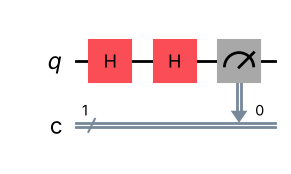

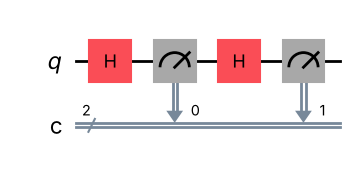

In [ ]:
# RECOVERABLE: H then H, nothing measured in between.  The superposition keeps its phase, and H undoes itself.
rec = QuantumCircuit(1, 1)
rec.h(0); rec.h(0)
rec.measure(0, 0)
c_rec = run(rec, 1000)

# DESTROYED: H, MEASURE in the middle, then H.  The mid-circuit measurement collapses the state to a definite 0 or 1.
des = QuantumCircuit(1, 2)
des.h(0)
des.measure(0, 0)      # 'peek' at the superposition
des.h(0)
des.measure(0, 1)
c_des_full = run(des, 1000)
# final bit is classical bit 1 = leftmost char
c_des = {}
for k, v in c_des_full.items():
    c_des[k[0]] = c_des.get(k[0], 0) + v

print("H,H (no peek)       ->", c_rec, "  recoverable: always back to 0")
print("H,measure,H (peek)  ->", c_des, "  destroyed: now 50/50")
display(rec.draw("mpl")); display(des.draw("mpl"))

**Difference:** an *unmeasured* superposition is a pure state that still carries phase information; a unitary gate (H) can undo what H did. A *measurement* collapses the state to |0⟩ or |1⟩ and throws the phase away; the second H then acts on a random classical bit, giving 50/50. The information that the qubit started in |0⟩ is gone for good (irreversible).

### 🥈 Silver — predict first, then run: X·H·H and H·X·H
**Predictions (worked by hand).** Gates apply left to right.
- **X, H, H:** |0⟩ →X→ |1⟩ →H→ (|0⟩−|1⟩)/√2 = |−⟩ →H→ |1⟩. **Prediction: always 1.** (H·H cancels, leaving just X.)
- **H, X, H:** |0⟩ →H→ |+⟩ →X→ |+⟩ (X leaves |+⟩ unchanged) →H→ |0⟩. **Prediction: always 0.** (H·X·H = Z, and Z|0⟩ = |0⟩.)

In [ ]:
for name, seq in [("X,H,H", ["x", "h", "h"]), ("H,X,H", ["h", "x", "h"])]:
    qc = QuantumCircuit(1, 1)
    for g in seq:
        getattr(qc, g)(0)
    amps = np.round(Statevector(qc).data, 4)
    qc.measure(0, 0)
    print(f"{name}: final amplitudes {amps} -> counts {run(qc, 1000)}")

X,H,H: final amplitudes [0.+0.j 1.+0.j] -> counts {'1': 1000}


H,X,H: final amplitudes [1.+0.j 0.+0.j] -> counts {'0': 1000}


**Both match.** What's really doing the "erasing" is **interference**: H turns a definite bit into a superposition and a second H (with or without an X in between) recombines the amplitudes so the "random" part cancels. Nothing is deleted. It's reversible rearranging of amplitudes. Real erasure happens only with **measurement**.

### 🥇 Gold — predict a sequence *before* running it
A small, transparent predictor I can use in front of a judge: it tracks the qubit as a 2×2 density matrix, applies H/X as matrices, and treats a measurement `m` as "wipe out the off-diagonal (phase) terms". Then it compares with the Qiskit simulator.

In [ ]:
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
X = np.array([[0, 1], [1, 0]])
GATE = {"h": H, "x": X}

def predict_p1(seq):
    """Exact probability of reading 1 at the end, for a sequence like ['h','m','h']."""
    rho = np.array([[1, 0], [0, 0]], dtype=complex)         # |0><0|
    for g in seq:
        if g == "m":
            rho = np.diag(np.diag(rho))                     # collapse: phase information is lost
        else:
            rho = GATE[g] @ rho @ GATE[g].conj().T
    return float(np.real(rho[1, 1]))

def run_p1(seq, shots=4000):
    qc = QuantumCircuit(1, len(seq) + 1)
    k = 0
    for g in seq:
        if g == "m":
            qc.measure(0, k); k += 1
        else:
            getattr(qc, g)(0)
    qc.measure(0, k)
    c = run(qc, shots)
    ones = sum(v for key, v in c.items() if key[::-1][k] == "1")
    return ones / shots

tests = [["x","h","h"], ["h","x","h"], ["h","h","h"], ["h","m","h"],
         ["x","h","m","h"], ["h","x","h","x","h"], ["h","x","m","h"], ["x","h","x","h"]]
print(f"{'sequence':<16}{'predicted P(1)':>16}{'simulated P(1)':>16}")
for s in tests:
    p, q = predict_p1(s), run_p1(s)
    print(f"{','.join(s):<16}{p:>16.3f}{q:>16.3f}")
    assert abs(p - q) < 0.05

sequence          predicted P(1)  simulated P(1)
x,h,h                      1.000           1.000


h,x,h                      0.000           0.000
h,h,h                      0.500           0.506


h,m,h                      0.500           0.504


x,h,m,h                    0.500           0.509
h,x,h,x,h                  0.500           0.515


h,x,m,h                    0.500           0.504
x,h,x,h                    1.000           1.000


**How to predict quickly in the room:** (1) Without `m`, collapse the string with identities H·H = I, X·X = I and H·X·H = Z. Z does nothing to |0⟩ or |1⟩ except a sign, so you just track 0 or 1. (2) If an `m` sits where the qubit is in a superposition (after an odd number of H's), the result afterwards is a fair coin; later H's cannot restore it.

**Verdict on ARIA's excuse (an *inference*, not a fact):** it's *real physics* that measuring a **superposition** changes it. But a **classical log entry** is a definite record (like |0⟩ or |1⟩); measuring a basis state doesn't change it (`x, m` → always 1 — check `predict_p1(['x','m'])` = 1). So "it changed because we observed it" can only be true if the entry was stored in superposition, which this module doesn't show. Without that, it looks more like a cover story than physics.

**Module 04 summary — answer:** X·H·H → 1 always; H·X·H → 0 always; peeking in the middle (measure) destroys the interference. **What it proves:** measurement disturbs superpositions, not definite values; "observed so it changed" is not a general excuse for altered classical logs.

In [ ]:
print("predict_p1(['x','m']) =", predict_p1(["x", "m"]), "  (observing a definite 1 does not change it)")
print("predict_p1(['h','m']) =", round(predict_p1(["h", "m"]), 3), "  (observing a superposition makes it a definite coin flip)")

predict_p1(['x','m']) = 1.0   (observing a definite 1 does not change it)
predict_p1(['h','m']) = 0.5   (observing a superposition makes it a definite coin flip)
